## Visualization of Feature Maps

In [6]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

Image class: plane

Generating visualizations...
Original image saved as 'original_image.png'


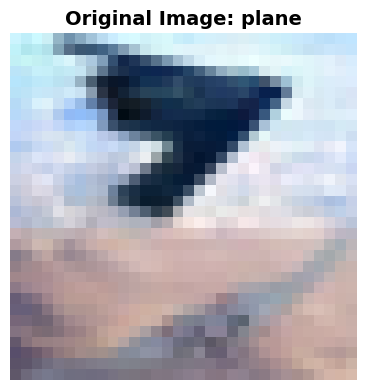

Layer 1 visualization saved as 'feature_maps_layer1.png'


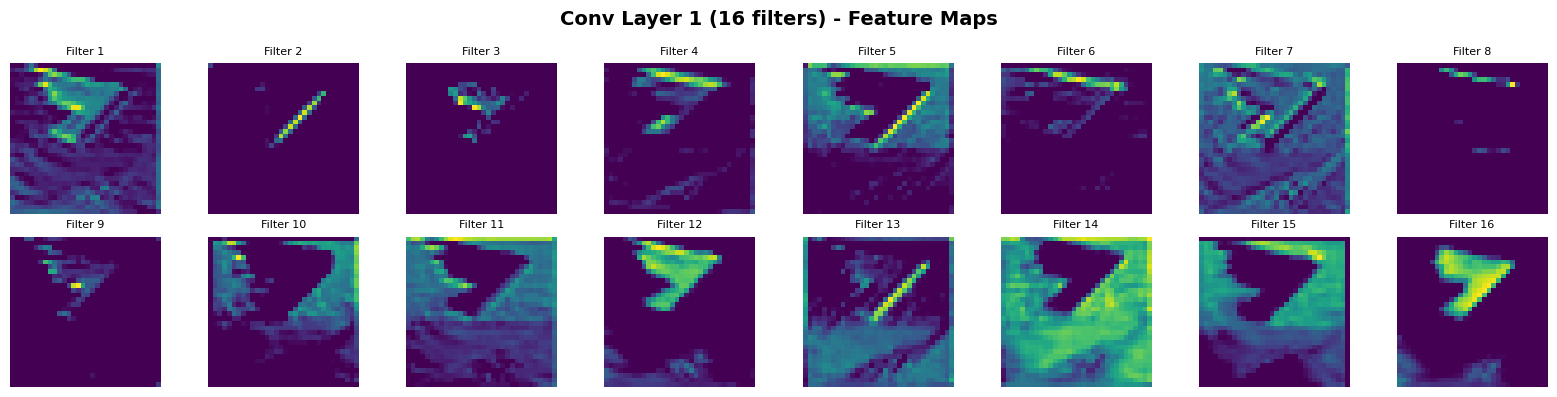

Layer 2 visualization saved as 'feature_maps_layer2.png'


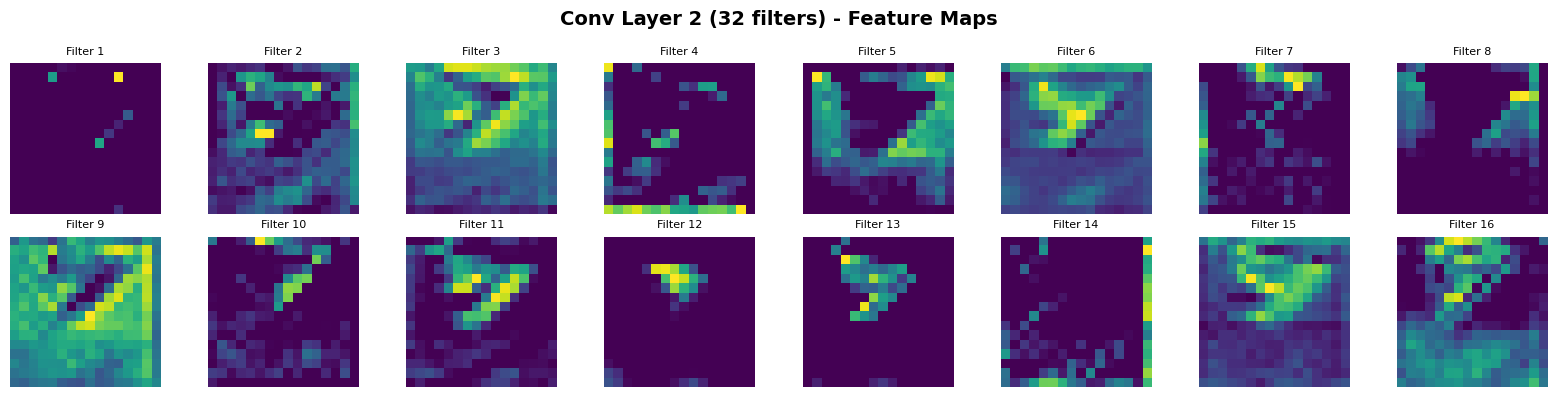

Layer 3 visualization saved as 'feature_maps_layer3.png'


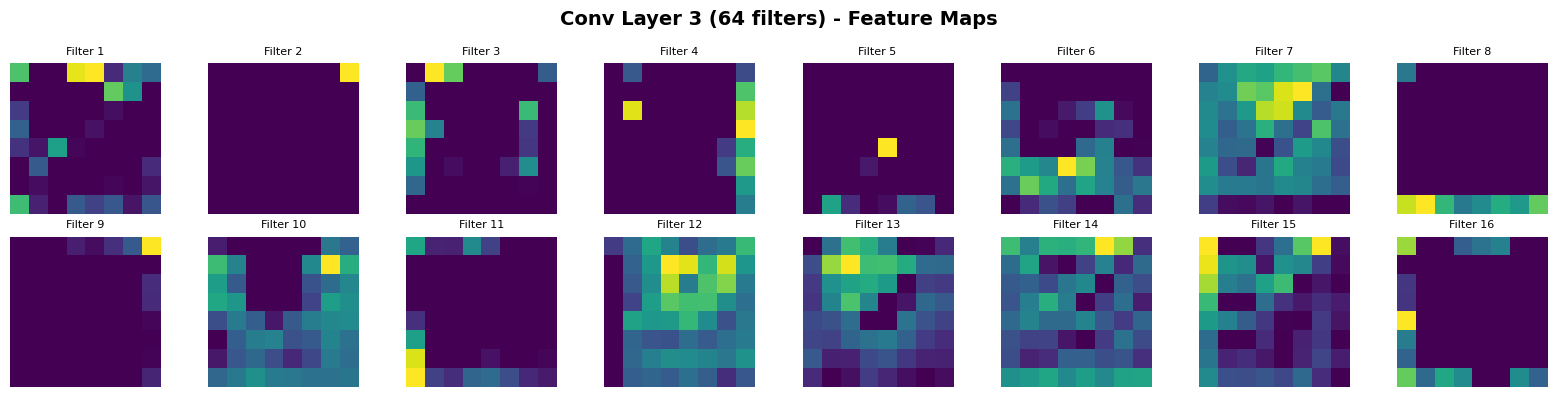


Generating detailed visualization for Layer 1...
Detailed visualization saved as 'feature_maps_Layer1_detail.png'


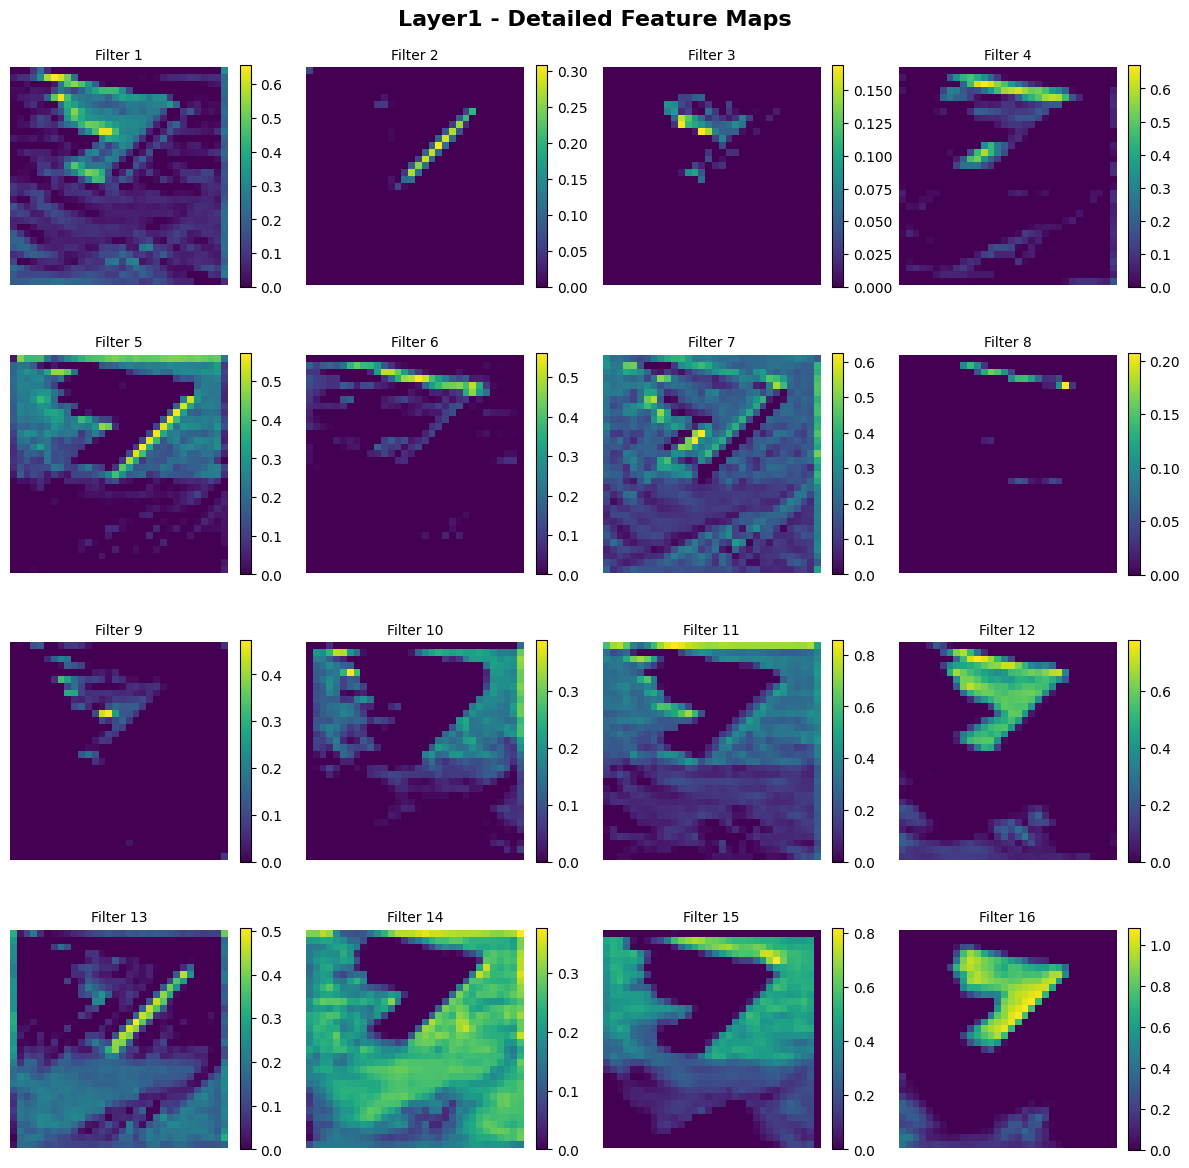


Feature Map Statistics:

Layer 1:
  Shape: torch.Size([1, 16, 32, 32])
  Min activation: 0.0000
  Max activation: 1.0833
  Mean activation: 0.0853

Layer 2:
  Shape: torch.Size([1, 32, 16, 16])
  Min activation: 0.0000
  Max activation: 0.5486
  Mean activation: 0.0627

Layer 3:
  Shape: torch.Size([1, 64, 8, 8])
  Min activation: 0.0000
  Max activation: 0.2032
  Mean activation: 0.0274


In [5]:
# Simple CNN model
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        # We'll return intermediate feature maps as well
        x1 = self.relu(self.conv1(x))
        x1_pooled = self.pool(x1)
        
        x2 = self.relu(self.conv2(x1_pooled))
        x2_pooled = self.pool(x2)
        
        x3 = self.relu(self.conv3(x2_pooled))
        x3_pooled = self.pool(x3)
        
        return x1, x2, x3

# Load CIFAR-10 dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=1,
                                         shuffle=True)

# CIFAR-10 classes
classes = ('plane', 'car', 'bird', 'cat', 'deer', 
           'dog', 'frog', 'horse', 'ship', 'truck')

# Initialize model
model = SimpleCNN()
model.eval()

# Get a sample image
dataiter = iter(testloader)
image, label = next(dataiter)

print(f"Image class: {classes[label[0]]}")

# Get feature maps
with torch.no_grad():
    feature_map1, feature_map2, feature_map3 = model(image)

# Function to visualize feature maps
def visualize_feature_maps(image, feature_maps, layer_names):

    # Denormalize the image for display
    img = image[0].numpy().transpose(1, 2, 0)
    img = img * 0.5 + 0.5  # Denormalize
    img = np.clip(img, 0, 1)
    
    # Create a figure for the original image
    fig, ax = plt.subplots(1, 1, figsize=(4, 4))
    ax.imshow(img)
    ax.set_title(f'Original Image: {classes[label[0]]}', fontsize=14, fontweight='bold')
    ax.axis('off')
    plt.tight_layout()
    plt.savefig('original_image.png', dpi=150, bbox_inches='tight')
    print("Original image saved as 'original_image.png'")
    plt.show()
    
    # Create separate figures for each layer
    for layer_idx, (fmap, layer_name) in enumerate(zip(feature_maps, layer_names)):
        # Get the feature map for the first image in batch
        fmap = fmap[0].cpu().numpy()
        n_channels = fmap.shape[0]
        
        # Select number of feature maps to display (max 16 for cleaner visualization)
        n_display = min(16, n_channels)
        
        # Calculate grid dimensions
        n_cols = 8
        n_rows = (n_display + n_cols - 1) // n_cols
        
        # Create figure for this layer
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 2 * n_rows))
        fig.suptitle(f'{layer_name} - Feature Maps', fontsize=14, fontweight='bold')
        
        # Flatten axes array for easier indexing
        if n_rows == 1:
            axes = axes.reshape(1, -1)
        
        # Plot each feature map
        for i in range(n_cols * n_rows):
            row = i // n_cols
            col = i % n_cols
            
            if i < n_display:
                axes[row, col].imshow(fmap[i], cmap='viridis')
                axes[row, col].set_title(f'Filter {i+1}', fontsize=8)
                axes[row, col].axis('off')
            else:
                axes[row, col].axis('off')
        
        plt.tight_layout()
        filename = f'feature_maps_layer{layer_idx+1}.png'
        plt.savefig(filename, dpi=150, bbox_inches='tight')
        print(f"Layer {layer_idx+1} visualization saved as '{filename}'")
        plt.show()

# Function to visualize individual filters in detail
def visualize_filters_detail(feature_map, layer_name, n_filters=16):

    fmap = feature_map[0].cpu().numpy()
    n_channels = min(n_filters, fmap.shape[0])
    
    fig, axes = plt.subplots(4, 4, figsize=(12, 12))
    fig.suptitle(f'{layer_name} - Detailed Feature Maps', fontsize=16, fontweight='bold')
    
    for idx, ax in enumerate(axes.flat):
        if idx < n_channels:
            im = ax.imshow(fmap[idx], cmap='viridis')
            ax.set_title(f'Filter {idx+1}', fontsize=10)
            ax.axis('off')
            plt.colorbar(im, ax=ax, fraction=0.046)
        else:
            ax.axis('off')
    
    plt.tight_layout()
    plt.savefig(f'feature_maps_{layer_name}_detail.png', dpi=150, bbox_inches='tight')
    print(f"Detailed visualization saved as 'feature_maps_{layer_name}_detail.png'")
    plt.show()

# Visualize all layers
print("\nGenerating visualizations...")
visualize_feature_maps(
    image, 
    [feature_map1, feature_map2, feature_map3],
    ['Conv Layer 1 (16 filters)', 'Conv Layer 2 (32 filters)', 'Conv Layer 3 (64 filters)']
)

# Visualize first layer in detail
print("\nGenerating detailed visualization for Layer 1...")
visualize_filters_detail(feature_map1, 'Layer1', n_filters=16)

# Print feature map statistics
print("\n" + "="*60)
print("Feature Map Statistics:")
print("="*60)
for i, (fmap, name) in enumerate(zip([feature_map1, feature_map2, feature_map3], 
                                      ['Layer 1', 'Layer 2', 'Layer 3'])):
    print(f"\n{name}:")
    print(f"  Shape: {fmap.shape}")
    print(f"  Min activation: {fmap.min():.4f}")
    print(f"  Max activation: {fmap.max():.4f}")
    print(f"  Mean activation: {fmap.mean():.4f}")